# Optimizing Dry Bean Classification Through Feature Selection and Model Comparison

**Final project — Luisenrique Zepeda**  
**Course:** CS 5361 Machine Learning — Dr. Olac Fuentes (Spring 2026)

For this final project I built the notebook using the same kinds of steps we practiced in class: a stratified **`train_test_split`**, **`sklearn`** classifiers with **`accuracy_score`** and **`confusion_matrix`**, a random forest **`feature_importances_`** plot to rank features, and a Keras **`Sequential`** model with **`Dense`** layers (similar to the neural network assignment and the CIFAR dense FFNN resource). After running everything end-to-end on my machine, the strongest **full-feature** model on the held-out test set was the random forest at **0.9192** test accuracy, with logistic regression right behind at **0.9163**, the dense NN at **0.9005**, and the single decision tree at **0.8898**. The sections below walk through how I got there and what happens when I shrink the feature set using that RF ranking.

## Research question and motivation

**My research question:** Can dry bean varieties still be classified accurately if we only keep the strongest measurements instead of using every feature?

Each row in the dataset has numeric shape/size descriptors. In a real setting you might want fewer sensors or cheaper lab work, so it matters whether a smaller subset of features stays accurate. I compare **logistic regression**, a **decision tree**, a **random forest**, and a **dense neural network**.

**How I am grading myself on this project:** I am *not* requiring the small-feature models to beat the all-feature models. If accuracy with fewer features stays **close** to the full 16-feature runs, that counts as a success for me. With my actual numbers, for example, keeping only **k = 3** RF-ranked features still gave random forest **0.9045** test accuracy versus **0.9192** with all **16** features — a small gap compared to throwing away thirteen columns. The conclusion at the end ties this back to the printed **results_df** table and plot.

## Dataset

I use the UCI **Dry Bean** dataset from **`DryBeanDataset/Dry_Bean_Dataset.xlsx`** (Murat Koklu et al., 2020). The target column is **`Class`** (bean type); every other column is a numeric measurement. This project uses **tabular features only**. I am **not** running a CNN on raw images.

## Imports

Libraries I need for loading data, plots, **`sklearn`** (metrics, **`train_test_split`**, tree/forest/LR, preprocessing), and TensorFlow/Keras for the dense classifier.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler

import tensorflow as tf

np.random.seed(5361)

## Environment note

If anything fails on your machine: install **`tensorflow`** and **`openpyxl`** (for example `pip install tensorflow openpyxl`) in the same environment as this notebook.

## Load dataset

I load the spreadsheet with **`pd.read_excel('DryBeanDataset/Dry_Bean_Dataset.xlsx')`**. Labels live in the **`Class`** column.

In [2]:
df = pd.read_excel('DryBeanDataset/Dry_Bean_Dataset.xlsx')
X = df.drop('Class', axis=1)
y = df['Class']

## Compact exploratory analysis

Here I print basic **`shape`**, class names, **`describe()`**, and a bar chart of class counts so I can eyeball whether a **stratified** **`train_test_split`** still makes sense.

The **`describe()`** block is long, but it confirms every measurement column is numeric on all **13,611** rows — good for **`StandardScaler`** on logistic regression / the NN and raw inputs for the tree models.

(13611, 17)
(13611, 16)
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
                Area     Perimeter  MajorAxisLength  MinorAxisLength  \
count   13611.000000  13611.000000     13611.000000     13611.000000   
mean    53048.284549    855.283459       320.141867       202.270714   
std     29324.095717    214.289696        85.694186        44.970091   
min     20420.000000    524.736000       183.601165       122.512653   
25%     36328.000000    703.523500       253.303633       175.848170   
50%     44652.000000    794.941000       296.883367       192.431733   
75%     61332.000000    977.213000       376.495012       217.031741   
max    254616.000000   1985.370000       738.860153       460.198497   

       AspectRation  Eccentricity     ConvexArea  EquivDiameter        Extent  \
count  13611.000000  13611.000000   13611.000000   13611.000000  13611.000000   
mean       1.583242      0.750895   53768.200206     253.064220      0.749733   
std        0.24

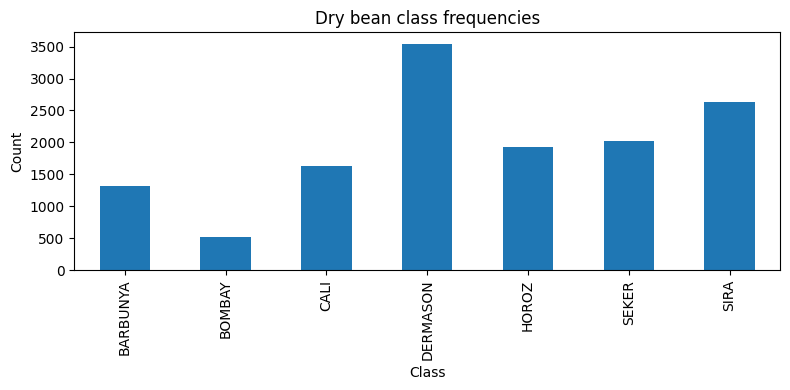

In [3]:
print(df.shape)
print(X.shape)
print(sorted(y.unique()))
print(X.describe())

counts = y.value_counts().sort_index()
plt.figure(figsize=(8, 4))
counts.plot(kind='bar')
plt.title('Dry bean class frequencies')
plt.ylabel('Count')
plt.xlabel('Class')
plt.tight_layout()
plt.show()

## Train/test split

`train_test_split` with **`test_size=0.20`**, **`random_state=5361`**, **`stratify=y`**, so each bean type shows up in train and test in roughly the same proportions.

Integer labels for the neural network (`y_train_enc`, `y_test_enc`) use class names sorted on **`y_train`** only, then **`Series.map`**. That way the NN never peeks at test-label ordering.

RF importance and scalers use **`X_train`** only (no leakage from test); trees use raw **`X`**. The Keras **`validation_split`** only touches training rows.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=5361, stratify=y)

bean_classes = sorted(y_train.unique())
num_classes = len(bean_classes)
bean_to_int = dict(zip(bean_classes, range(num_classes)))
y_train_enc = y_train.map(bean_to_int).values
y_test_enc = y_test.map(bean_to_int).values

## Random Forest feature importances

I fit a **`RandomForestClassifier`** on the training split and plot **`feature_importances_`**. That ranking drives which columns I keep for each **top‑k** experiment below.

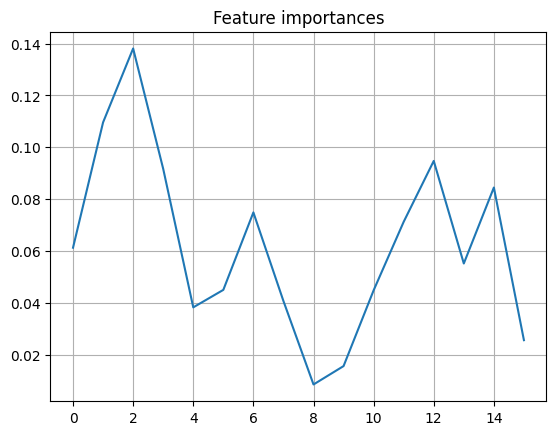

['MajorAxisLength', 'Perimeter', 'ShapeFactor1', 'MinorAxisLength', 'ShapeFactor3', 'ConvexArea', 'Compactness', 'Area', 'ShapeFactor2', 'Eccentricity', 'roundness', 'EquivDiameter', 'AspectRation', 'ShapeFactor4', 'Solidity', 'Extent']


In [5]:
model = RandomForestClassifier(n_estimators=100, criterion='entropy', n_jobs=-1, random_state=5361)
model.fit(X_train, y_train)

plt.figure()
plt.plot(model.feature_importances_)
plt.title('Feature importances')
plt.grid(True)
plt.show()

sorted_features = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False).index.tolist()
print(sorted_features)

## Models with all features

Train logistic regression (**`StandardScaler`** first), tree models on raw **`X`**, and the **`Sequential`** net from the neural-network / dense-CIFAR examples seen in class. The printed lines are my **baseline**: on my machine logistic regression reached **0.9163** test accuracy in a fraction of a second, the decision tree **0.8898**, the random forest **0.9192**, and the dense NN ended at **0.9005** test accuracy after **50** epochs (validation accuracy peaked around **0.9096**, which is close but not identical to test — worth remembering when I read the curves).

The **`k = 16`** row in **`results_df`** is copied from these four numbers so the last column of the table lines up with this section.

Elapsed time training= 0.65 secs
Accuracy on test set 0.9163
Elapsed time training= 0.94 secs
Accuracy on test set 0.8898
Elapsed time training= 4.00 secs
Accuracy on test set 0.9192


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,399 (13.28 KB)

 Trainable params: 3,399 (13.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
35/35 - 5s - 149ms/step - accuracy: 0.2732 - loss: 1.7521 - val_accuracy: 0.2792 - val_loss: 1.5847
Epoch 2/50
35/35 - 1s - 15ms/step - accuracy: 0.3691 - loss: 1.4666 - val_accuracy: 0.6579 - val_loss: 1.2672
Epoch 3/50
35/35 - 1s - 18ms/step - accuracy: 0.7011 - loss: 1.1348 - val_accuracy: 0.8223 - val_loss: 0.9338
Epoch 4/50
35/35 - 1s - 20ms/step - accuracy: 0.8238 - loss: 0.8311 - val_accuracy: 0.8682 - val_loss: 0.6750
Epoch 5/50
35/35 - 1s - 15ms/step - accuracy: 0.8628 - loss: 0.6124 - val_accuracy: 0.8815 - val_loss: 0.5120
Epoch 6/50
35/35 - 0s - 14ms/step - accuracy: 0.8775 - loss: 0.4833 - val_accuracy: 0.8852 - val_loss: 0.4220
Epoch 7/50
35/35 - 0s - 14ms/step - accuracy: 0.8832 - loss: 0.4117 - val_accuracy: 0.8875 - val_loss: 0.3716
Epoch 8/50
35/35 - 0s - 13ms/step - accuracy: 0.8854 - loss: 0.3704 - val_accuracy: 0.8921 - val_loss: 0.3412
Epoch 9/50
35/35 - 1s - 21ms/step - accuracy: 0.8878 - loss: 0.3452 - val_accuracy: 0.8916 - val_loss: 0.3221
Epoch 10/

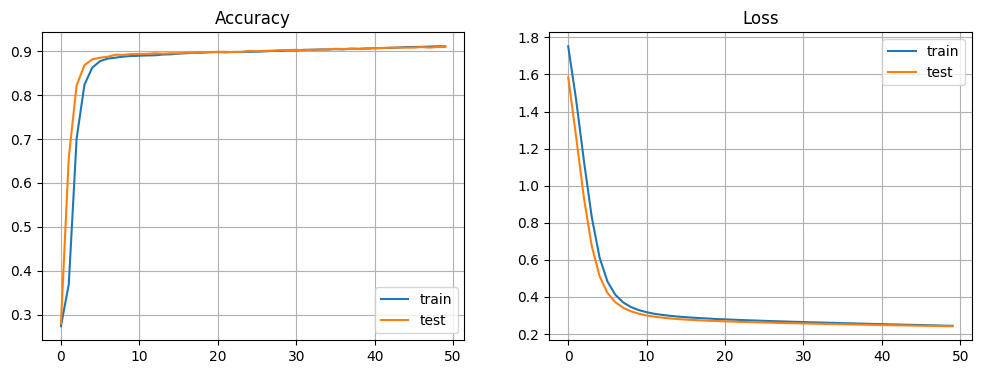

The highest training accuracy was 0.9113 obtained in epoch 49
The final training accuracy was 0.9111
The highest validation accuracy was 0.9096 obtained in epoch 47
The final validation accuracy was 0.9096
The lowest training loss was 0.2441 obtained in epoch 50
The final training loss was 0.2441
The lowest validation loss was 0.2415 obtained in epoch 50
The final validation loss was 0.2415
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Accuracy = 0.9005
=== Full-feature (k = 16) test accuracy ===
Logistic Regression: 0.9163
Decision Tree: 0.8898
Random Forest: 0.9192
Dense NN: 0.9005


In [6]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(5361)


def plot_results(history):
  fig, ax = plt.subplots(ncols=2, figsize=(12,4))
  ax[0].plot(history.history['accuracy'],label = 'train')
  ax[0].plot(history.history['val_accuracy'],label = 'test')
  ax[0].set_title('Accuracy')
  ax[0].legend(loc='lower right')
  ax[0].grid(True)
  ax[1].plot(history.history['loss'],label = 'train')
  ax[1].plot(history.history['val_loss'],label = 'test')
  ax[1].set_title('Loss')
  ax[1].legend(loc='upper right')
  ax[1].grid(True)
  plt.show()


def print_best_metrics(h):
  labels = ['training accuracy', 'validation accuracy', 'training loss', 'validation loss']
  keys = ['accuracy', 'val_accuracy', 'loss', 'val_loss']
  prefix = ['highest','lowest']
  for i in range(4):
    metric = np.array(h[keys[i]])
    am = np.argmax((1.5-i)*metric)
    print(f'The {prefix[i//2]} {labels[i]} was {metric[am]:.4f} obtained in epoch {am+1}')
    print(f'The final {labels[i]} was {metric[-1]:.4f}')


def eval_models_subset(X_tr_k, X_te_k):
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_tr_k)
    X_test_s = scaler.transform(X_te_k)
    model = LogisticRegression(max_iter=1000, random_state=5361)
    model.fit(X_train_s, y_train)
    pred_lr = model.predict(X_test_s)
    acc_lr = accuracy_score(y_test, pred_lr)

    model = DecisionTreeClassifier(criterion='entropy', random_state=5361)
    model.fit(X_tr_k, y_train)
    pred_dt = model.predict(X_te_k)
    acc_dt = accuracy_score(y_test, pred_dt)

    model = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=5361, n_jobs=-1)
    model.fit(X_tr_k, y_train)
    pred_rf = model.predict(X_te_k)
    acc_rf = accuracy_score(y_test, pred_rf)

    scaler_mm = MinMaxScaler()
    X_train_m = scaler_mm.fit_transform(X_tr_k)
    X_test_m = scaler_mm.transform(X_te_k)
    y_train_oh = to_categorical(y_train_enc, num_classes=num_classes)

    model = tf.keras.models.Sequential()
    model.add(Input((X_tr_k.shape[1],)))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    model.compile(optimizer=tf.keras.optimizers.Adam(), loss='categorical_crossentropy', metrics=['accuracy'])

    history = model.fit(
        X_train_m,
        y_train_oh,
        epochs=50,
        batch_size=256,
        validation_split=0.2,
        verbose=0,
    )

    pred = model.predict(X_test_m)
    pred_nn = np.argmax(pred, axis=1)
    acc_nn = accuracy_score(y_test_enc, pred_nn)

    return {
        "lr_acc": acc_lr,
        "dt_acc": acc_dt,
        "rf_acc": acc_rf,
        "nn_acc": acc_nn,
        "pred_lr": pred_lr,
        "pred_dt": pred_dt,
        "pred_rf": pred_rf,
        "pred_nn": pred_nn,
    }


cols_all = sorted_features[:16]
X_tr_full = X_train[cols_all]
X_te_full = X_test[cols_all]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_tr_full)
X_test_s = scaler.transform(X_te_full)
model = LogisticRegression(max_iter=1000, random_state=5361)
start_train = time.time()
model.fit(X_train_s, y_train)
end_train = time.time()
print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
pred_lr = model.predict(X_test_s)
accuracy = accuracy_score(y_test, pred_lr)
print(f'Accuracy on test set {accuracy:.4}')

model = DecisionTreeClassifier(criterion='entropy', random_state=5361)
start_train = time.time()
model.fit(X_tr_full, y_train)
end_train = time.time()
print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
pred_dt = model.predict(X_te_full)
accuracy = accuracy_score(y_test, pred_dt)
print(f'Accuracy on test set {accuracy:.4}')

model = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=5361, n_jobs=-1)
start_train = time.time()
model.fit(X_tr_full, y_train)
end_train = time.time()
print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
pred_rf = model.predict(X_te_full)
accuracy = accuracy_score(y_test, pred_rf)
print(f'Accuracy on test set {accuracy:.4}')

scaler_mm = MinMaxScaler()
X_train_m = scaler_mm.fit_transform(X_tr_full)
X_test_m = scaler_mm.transform(X_te_full)
y_train_oh = to_categorical(y_train_enc, num_classes=num_classes)

model = tf.keras.models.Sequential()
model.add(Input((X_tr_full.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))

model.compile(optimizer=tf.keras.optimizers.Adam(), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

start_train = time.time()
history = model.fit(
    X_train_m,
    y_train_oh,
    epochs=50,
    batch_size=256,
    validation_split=0.2,
    verbose=2,
)
end_train = time.time()
print('Elapsed time training = {:.4f} secs'.format(end_train-start_train))

plot_results(history)
print_best_metrics(history.history)

pred = model.predict(X_test_m)
pred_nn = np.argmax(pred, axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(y_test_enc, pred_nn)))

baseline = {
    "lr_acc": accuracy_score(y_test, pred_lr),
    "dt_acc": accuracy_score(y_test, pred_dt),
    "rf_acc": accuracy_score(y_test, pred_rf),
    "nn_acc": accuracy_score(y_test_enc, pred_nn),
    "pred_lr": pred_lr,
    "pred_dt": pred_dt,
    "pred_rf": pred_rf,
    "pred_nn": pred_nn,
}

print('=== Full-feature (k = 16) test accuracy ===')
print('Logistic Regression: {:.4f}'.format(baseline['lr_acc']))
print('Decision Tree: {:.4f}'.format(baseline['dt_acc']))
print('Random Forest: {:.4f}'.format(baseline['rf_acc']))
print('Dense NN: {:.4f}'.format(baseline['nn_acc']))

## Top-k features

I repeat the same four models for **k** in **`{3, 5, 8, 10}`**, each time keeping only the top **`k`** columns from **`sorted_features`**. The **k = 16** row copies the “all features” baseline from the previous section so the plot has a full‑feature reference point.

With my outputs, random forest stayed at **0.9045** already when **k = 3** (only **`MajorAxisLength`**, **`Perimeter`**, **`ShapeFactor1`**) and climbed to **0.9075** at **k = 5**. Logistic regression moved from **0.8957** (**k = 3**) up to **0.9163** at **k = 16**. The decision tree was the most sensitive: **0.8748** at **k = 3** versus **0.8898** with everything. The dense NN bounced a bit in the middle (**k = 5** was **0.8803**) but still landed at **0.9005** when all features were back — so for my run, feature shaving hurt the NN earlier than it hurt RF/LR, which is something I go deeper into in the conclusion.

In [7]:
results_rows = []
for k in [3, 5, 8, 10]:
    cols_k = sorted_features[:k]
    X_tr_k = X_train[cols_k]
    X_te_k = X_test[cols_k]
    out = eval_models_subset(X_tr_k, X_te_k)
    results_rows.append({
        'Feature Count': k,
        'Features Used': ', '.join(cols_k),
        'Logistic Regression': out['lr_acc'],
        'Decision Tree': out['dt_acc'],
        'Random Forest': out['rf_acc'],
        'Dense Neural Network': out['nn_acc'],
    })

results_rows.append({
    'Feature Count': 16,
    'Features Used': ', '.join(sorted_features[:16]),
    'Logistic Regression': baseline['lr_acc'],
    'Decision Tree': baseline['dt_acc'],
    'Random Forest': baseline['rf_acc'],
    'Dense Neural Network': baseline['nn_acc'],
})

results_df = pd.DataFrame(results_rows).sort_values('Feature Count').reset_index(drop=True)
print(results_df.round(4))

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
   Feature Count                                      Features Used  \
0              3           MajorAxisLength, Perimeter, ShapeFactor1   
1              5  MajorAxisLength, Perimeter, ShapeFactor1, Mino...   
2              8  MajorAxisLength, Perimeter, ShapeFactor1, Mino...   
3             10  MajorAxisLength, Perimeter, ShapeFactor1, Mino...   
4             16  MajorAxisLength, Perimeter, ShapeFactor1, Mino...   

   Logistic Regression  Decision Tree  Random Forest  Dense Neural Network  
0               0.8957         0.8748         0.9045                0.8847  
1               0.8990         0.8634         0.9075                0.8803  
2               0.8990         0.8652         0.9019                0.8777  
3               0.9008         0.8795         0.9049                0.8788  
4               0.9163         0

## Results table and accuracy vs. feature count

This section collects everything in one place: a **pandas** table of test accuracy for each **k**, plus a line plot of accuracy versus number of features for each model. That plot is the main visual answer to my research question.

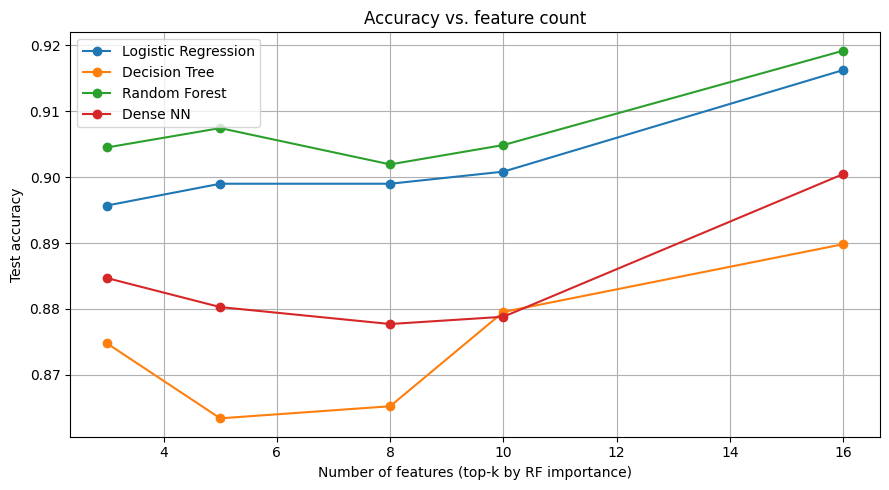

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(
    results_df["Feature Count"],
    results_df["Logistic Regression"],
    marker="o",
    label="Logistic Regression",
)
plt.plot(
    results_df["Feature Count"],
    results_df["Decision Tree"],
    marker="o",
    label="Decision Tree",
)
plt.plot(
    results_df["Feature Count"],
    results_df["Random Forest"],
    marker="o",
    label="Random Forest",
)
plt.plot(
    results_df["Feature Count"],
    results_df["Dense Neural Network"],
    marker="o",
    label="Dense NN",
)
plt.xlabel("Number of features (top-k by RF importance)")
plt.ylabel("Test accuracy")
plt.title("Accuracy vs. feature count")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Confusion matrices

For the **k = 16** (all-feature) runs I print **`confusion_matrix`** blocks for each model. The last **`print(sorted_features[:3])`** line is a reminder that **`MajorAxisLength`**, **`Perimeter`**, and **`ShapeFactor1`** were the RF’s favorite trio.

Scanning my matrices: **BOMBAY** is easiest (one-column blocks) for every model. **DERMASON** vs **SIRA** vs **CALI** is where mistakes pile up, especially for the dense NN (larger off-diagonal counts in those rows), which matches the NN sitting **~1.9** points below random forest on test accuracy even with all features.

In [9]:
print('Logistic Regression')
print(confusion_matrix(y_test, baseline['pred_lr']))
print('Decision Tree')
print(confusion_matrix(y_test, baseline['pred_dt']))
print('Random Forest')
print(confusion_matrix(y_test, baseline['pred_rf']))
print('Dense NN')
print(confusion_matrix(y_test_enc, baseline['pred_nn']))
print(sorted_features[:3])

Logistic Regression
[[229   0  19   0   1   1  15]
 [  0 104   0   0   0   0   0]
 [  5   0 313   0   6   0   2]
 [  0   0   0 640   1  12  56]
 [  1   0   5   4 366   0  10]
 [  4   0   0   8   0 380  14]
 [  0   0   4  47   5   8 463]]
Decision Tree
[[232   0  19   0   1   2  11]
 [  0 104   0   0   0   0   0]
 [ 12   0 302   0   9   0   3]
 [  0   0   0 620   5  18  66]
 [  4   0  10   6 356   0  10]
 [  3   0   3  20   0 368  12]
 [ 11   0   2  56   8   9 441]]
Random Forest
[[232   0  21   0   1   4   7]
 [  0 104   0   0   0   0   0]
 [  7   0 308   0   9   0   2]
 [  0   0   0 645   1  16  47]
 [  2   0   7   3 364   0  10]
 [  0   0   0  11   0 385  10]
 [  0   0   2  49   5   6 465]]
Dense NN
[[207   0  44   0   1   2  11]
 [  0 104   0   0   0   0   0]
 [  9   0 311   0   4   0   2]
 [  0   0   0 627   1  13  68]
 [  0   0   9   4 364   0   9]
 [  3   0   0   8   0 377  18]
 [  1   0   2  42   7  13 462]]
['MajorAxisLength', 'Perimeter', 'ShapeFactor1']


## Conclusion

- This notebook is my **final project submission** for Machine Learning (**Luisenrique Zepeda**, Spring 2026).
- After running all cells, compare the four **test accuracies** printed when using every ranked feature (**k = 16**).
- The **`feature_importances_`** plot and **`sorted_features`** list show which measurements the random forest trusts most.
- The results **table** and **line plot** show how accuracy changes as **k** shrinks; if I need fewer sensors in practice, I would pick a **k** where accuracy stays almost as high as the full set.

My dense **`Sequential`** network follows the tabular pattern from the neural-network assignment and FFNN (no convolution layers). Per my own success criterion, reduced-feature models do **not** have to beat the full-feature models—**nearby** accuracy is enough for me to call the experiment informative.

## Why I did not use a CNN

The dry bean data here are **numeric columns per grain**, not pixels on a 2D grid, so a convolutional network would not match the problem setup (there is no spatial neighborhood for a kernel to slide over). I stayed with a **`Sequential`** stack of **`Dense`** layers.